### Framing the problem

Questions:
a- What exactly is predicted?
b- Supervised or unsupervised? Regression or classification?
c- Which metric would you use and why?
d- whataa would a dumb baseline be?

Answers:
a- The count of bikes rented per hour
b- It's supervised and Regression
c- We should use RAE because RMSE punishes big misses more and if there are no bikes at a station during rush hour it would affect the metric a lot
d- A dumb baseline would be predicting the average cnt for every hour of the day

### Loading the data

In [37]:
import pandas as pd

df = pd.read_csv("../../data/hour.csv")

In [38]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Converting dteday column from string to date format

In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

In [56]:
df["dteday"][0]

Timestamp('2011-01-01 00:00:00')

In [57]:
df["dteday"] = pd.to_datetime(df["dteday"])

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

### Splitting the dataset

A random split wouldn't be a good idea in this case, because the amount of rentals doesn't vary much from hour to hour(making the generalization error rather optimistic). So it would make it very easy for the model to predict an hour's rental amounts if the hours around it are in the training set. Another reason is because of data drift, we want to test on the most up to date information since it's going to be used to make predictions in the near future.

In [89]:
df_train = df[(df["dteday"].dt.month < 10 )| (df["dteday"].dt.year != df["dteday"].dt.year.max())]
df_test = df[(df["dteday"].dt.month >= 10) & (df["dteday"].dt.year == df["dteday"].dt.year.max())]

### Visualization

In [90]:
df_train.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


<Axes: title={'center': 'Average rentals by hour of day'}, xlabel='hr'>

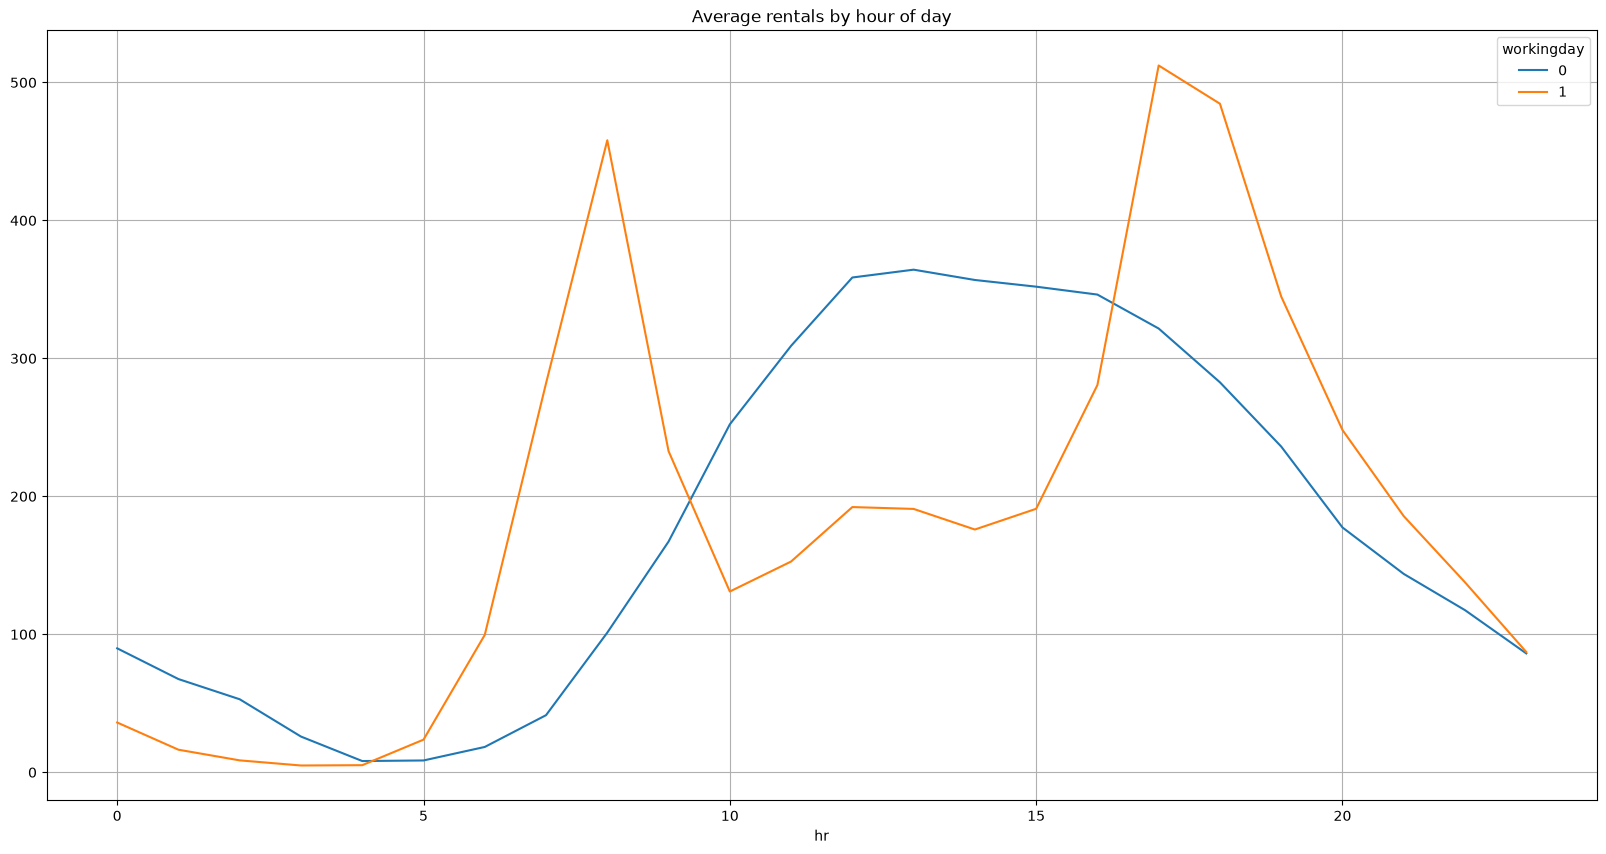

In [ ]:
df_train_cnt_per_hour = df_train.groupby(["hr", "workingday"])["cnt"].mean().unstack()
df_train_cnt_per_hour.plot(kind='line', figsize=(10,5), title="Average rentals by hour of day", grid=True)

This plot shows that when it's not a woorking day it the amount of rentals per hour distributes normally around 2 pm and when it's a working day it peaks between 5-10am and 3-8pm which seems to match usual work hours 

                         mean  count
weathersit                          
Clear              200.965257  10189
Mist / cloudy      168.389628   3760
Light rain / snow  108.386021   1259
Heavy rain / snow   74.333333      3


<Axes: title={'center': 'Average rentals by weather'}, xlabel='weathersit'>

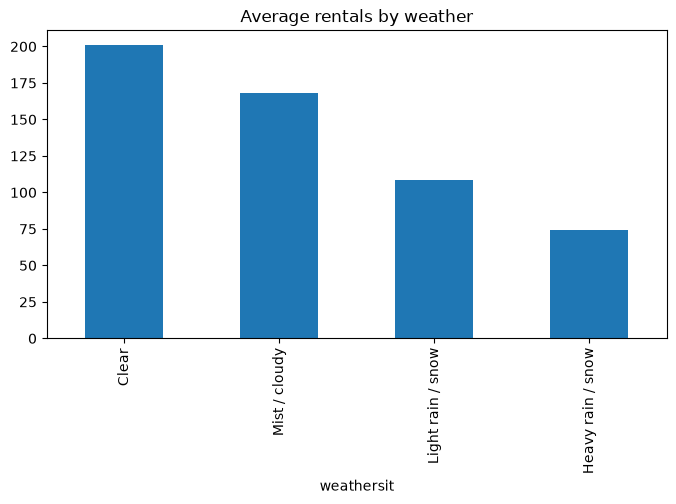

In [113]:
weather_labels = {1: "Clear", 2: "Mist / cloudy", 3: "Light rain / snow", 4: "Heavy rain / snow"}

weather = df_train.groupby("weathersit")["cnt"].agg(["mean", "count"])
weather.index = weather.index.map(weather_labels)
print(weather)

weather["mean"].plot(kind="bar", figsize=(8, 4), title="Average rentals by weather")

This plot shows that the most amount of rentals is done when the weather is sunny or partly clouded and the least amount when the weather conditions are extreme(heavy storm, snow, fog, etc). So the weather seems to be important to determine the count of rentals.

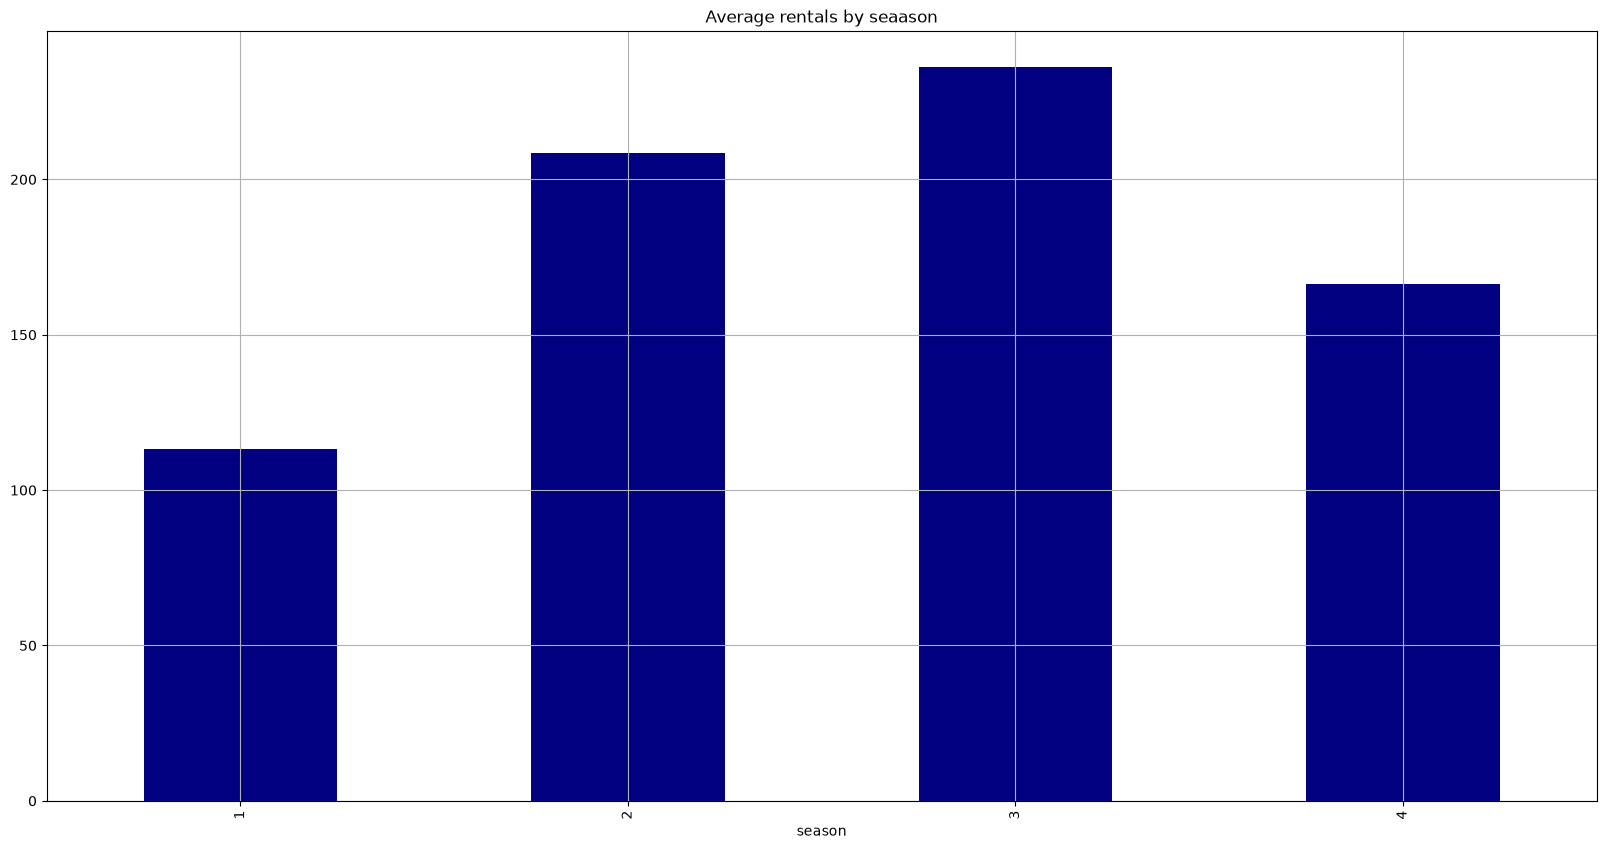

In [ ]:
df_train_per_season = df_train.groupby("season")["cnt"].mean()
df_train_per_season.plot(kind='bar', figsize=(10,5), title="Average rentals by seaason", grid=True)

This plot shows that the season with the most bike rentals is fall and the one with the least is spring by a relevant margin

### Identifying the Leak

There is a leak with the columns casual and registered since the sum of this is equal to the cnt and you wouldn't have this to make the predictions until the hour is over

In [94]:
(df_train["casual"] + df_train["registered"] == df_train["cnt"]).all()

np.True_

### Columns that need to be dropped before modeling

- casual and registered need to be dropped because of the leak we showed, the reason being that we wouldn't have those columns when using it to predict

- We can drop the instant column since it just seems to be an id/counter

- We can drop the column dteday since we already have that information, and maybe extract day from it and have it as a column